In [16]:

# ACTIVIDAD 3 - CONEXIÓN A SQL SERVER
# Importaciones y configuración de rutas

import os
import sys
from pathlib import Path

import pandas as pd
import certifi

# Localizar la carpeta principal del proyecto
carpeta_actual = Path.cwd().resolve()
carpeta_principal = (
    carpeta_actual.parent
    if carpeta_actual.name == "notebooks"
    else carpeta_actual
)

sys.path.insert(0, str(carpeta_principal))
os.chdir(carpeta_principal)

# Configurar certificados SSL
os.environ["SSL_CERT_FILE"] = certifi.where()

# Importar las funciones centralizadas
from esquema import nombre_tabla_sql, nombre_columna_sql
from config_conexion import conectar_sql_server

# Establecer conexión con SQL Server
conexion = conectar_sql_server()

# Verificar la base de datos
cursor = conexion.cursor()
cursor.execute("SELECT DB_NAME()")
resultado = cursor.fetchone()

print("¡Conexión exitosa!")
print("Base de datos:", resultado[0])

cursor.close()

# Mantenemos la conexión abierta para las siguientes consultas.


¡Conexión exitosa!
Base de datos: Sakila_Espanol


# Actividad 3 – Análisis y visualización narrativa

## Variante 5 – Rendimiento comercial por tienda y empleado

### Objetivo
Analizar cómo se distribuyen los ingresos entre las tiendas y los empleados,
identificando si las diferencias se deben al volumen de operaciones o al
ticket promedio.

### Métricas obligatorias
- Ingreso total por empleado y tienda.
- Cantidad de operaciones por empleado y tienda.
- Ticket promedio por empleado y tienda.
- Participación de cada empleado en el ingreso total de su tienda.
- Participación de cada tienda en el ingreso total del negocio.

### Técnicas obligatorias
- SQL Server: funciones de ventana `SUM(...) OVER (PARTITION BY ...)`.
- Python: operaciones vectorizadas con `groupby()` y `transform()`.

In [8]:

# Obtenemos los nombres físicos desde esquema.py
tablas = [
    nombre_tabla_sql("payment")[1:-1],
    nombre_tabla_sql("staff")[1:-1],
    nombre_tabla_sql("store")[1:-1]
]

consulta_columnas = """
SELECT
    TABLE_NAME,
    COLUMN_NAME,
    DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME IN (?, ?, ?)
ORDER BY TABLE_NAME, ORDINAL_POSITION;
"""

pd.read_sql(
    consulta_columnas,
    conexion,
    params=tuple(tablas)
)


/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_7152/2284594282.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(


,TABLE_NAME,COLUMN_NAME,DATA_TYPE
0,empleado,empleado_id,tinyint
1,empleado,nombre,varchar
2,empleado,apellido,varchar
3,empleado,direccion_id,smallint
4,empleado,foto,varbinary
5,empleado,email,varchar
6,empleado,tienda_id,tinyint
7,empleado,activo,bit
8,empleado,usuario,varchar
9,empleado,contrasena,varchar


In [9]:
# Actividad 3 - Métricas comerciales con funciones de ventana SQL

consulta_metricas_sql = f"""
WITH rendimiento AS (
    SELECT
        e.{nombre_columna_sql('staff', 'store_id')} AS tienda_id,
        e.{nombre_columna_sql('staff', 'staff_id')} AS empleado_id,
        CONCAT(e.{nombre_columna_sql('staff', 'first_name')}, ' ', e.{nombre_columna_sql('staff', 'last_name')}) AS empleado,
        SUM(p.{nombre_columna_sql('payment', 'amount')}) AS ingreso_total,
        COUNT(p.{nombre_columna_sql('payment', 'payment_id')}) AS cantidad_operaciones,
        AVG(p.{nombre_columna_sql('payment', 'amount')}) AS ticket_promedio
    FROM {nombre_tabla_sql('staff')} AS e
    LEFT JOIN {nombre_tabla_sql('payment')} AS p
        ON e.{nombre_columna_sql('staff', 'staff_id')} = p.{nombre_columna_sql('payment', 'staff_id')}
    GROUP BY
        e.{nombre_columna_sql('staff', 'store_id')} ,
        e.{nombre_columna_sql('staff', 'staff_id')} ,
        e.{nombre_columna_sql('staff', 'first_name')},
        e.{nombre_columna_sql('staff', 'last_name')}
),
participaciones AS (
    SELECT
        *,
        SUM(ingreso_total) OVER (
            PARTITION BY tienda_id
        ) AS ingreso_tienda
    FROM rendimiento
)
SELECT
    tienda_id,
    empleado_id,
    empleado,
    ingreso_total,
    cantidad_operaciones,
    ticket_promedio,
    ingreso_tienda,

    -- Participación del empleado en su tienda
    100.0 * ingreso_total
        / NULLIF(ingreso_tienda, 0)
        AS participacion_empleado_pct,

    -- Participación de la tienda en el negocio
    100.0 * ingreso_tienda
        / NULLIF(SUM(ingreso_total) OVER (), 0)
        AS participacion_tienda_pct

FROM participaciones
ORDER BY tienda_id, empleado_id;
"""

df_metricas_sql = pd.read_sql(consulta_metricas_sql, conexion)

df_metricas_sql

/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_7152/1618013582.py:52: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_metricas_sql = pd.read_sql(consulta_metricas_sql, conexion)


,tienda_id,empleado_id,empleado,ingreso_total,cantidad_operaciones,ticket_promedio,ingreso_tienda,participacion_empleado_pct,participacion_tienda_pct
0,1,1,Mike Hillyer,33482.50,8054,4.157251,33482.50,100.0,49.672465
1,2,2,Jon Stephens,33924.06,7990,4.245814,33924.06,100.0,50.327534


In [10]:
# Actividad 3 - Métricas y participaciones con pandas

df_metricas_pd = df_metricas_sql[
    [
        "tienda_id",
        "empleado_id",
        "empleado",
        "ingreso_total",
        "cantidad_operaciones"
    ]
].copy()

# Ticket promedio = ingresos / cantidad de operaciones
df_metricas_pd["ticket_promedio"] = (
    df_metricas_pd["ingreso_total"]
    / df_metricas_pd["cantidad_operaciones"].replace(0, float("nan"))
)

# Total de ingresos por tienda (groupby + transform)
df_metricas_pd["ingreso_tienda"] = (
    df_metricas_pd.groupby("tienda_id")["ingreso_total"]
    .transform("sum")
)

# Participación de cada empleado en su tienda
df_metricas_pd["participacion_empleado_pct"] = (
    100 * df_metricas_pd["ingreso_total"]
    / df_metricas_pd["ingreso_tienda"].replace(0, float("nan"))
)

# Participación de cada tienda en el total del negocio
total_negocio = df_metricas_pd["ingreso_total"].sum()

df_metricas_pd["participacion_tienda_pct"] = (
    100 * df_metricas_pd["ingreso_tienda"]
    / total_negocio
)

df_metricas_pd

,tienda_id,empleado_id,empleado,ingreso_total,cantidad_operaciones,ticket_promedio,ingreso_tienda,participacion_empleado_pct,participacion_tienda_pct
0,1,1,Mike Hillyer,33482.50,8054,4.157251,33482.50,100.0,49.672465
1,2,2,Jon Stephens,33924.06,7990,4.245815,33924.06,100.0,50.327535


In [11]:
import numpy as np

columnas_validar = [
    "ingreso_total",
    "cantidad_operaciones",
    "ticket_promedio",
    "ingreso_tienda",
    "participacion_empleado_pct",
    "participacion_tienda_pct"
]

validacion = np.allclose(
    df_metricas_sql[columnas_validar].to_numpy(dtype=float),
    df_metricas_pd[columnas_validar].to_numpy(dtype=float),
    rtol=1e-5,
    atol=1e-4,
    equal_nan=True
)

print("¿Coinciden los resultados SQL y pandas?", validacion)

¿Coinciden los resultados SQL y pandas? True


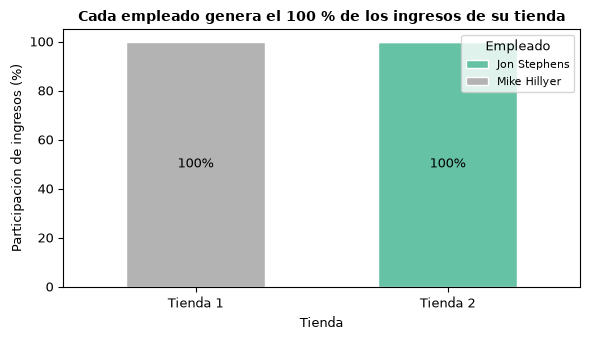

In [12]:

# ACTIVIDAD 3 GRÁFICO OBLIGATORIO DE BARRAS APILADAS AL 100 %
# Objetivo: visualizar la participación de cada empleado
# en los ingresos de su tienda.

import matplotlib.pyplot as plt
from pathlib import Path

# Organizamos los porcentajes por tienda y empleado.
datos_grafico = df_metricas_pd.pivot(
    index="tienda_id",
    columns="empleado",
    values="participacion_empleado_pct"
).fillna(0)

# Creamos el gráfico.
ax = datos_grafico.plot(
    kind="bar",
    stacked=True,
    figsize=(6, 3.5),
    colormap="Set2",
    edgecolor="white",
    width=0.55
)

# Agregamos el título y los nombres de los ejes.
ax.set_title(
    "Cada empleado genera el 100 % de los ingresos de su tienda",
    fontsize=10,
    fontweight="bold"
)

ax.set_xlabel("Tienda", fontsize=9)
ax.set_ylabel("Participación de ingresos (%)", fontsize=9)

# Establecemos la escala de porcentajes.
ax.set_ylim(0, 105)

# Ajustamos el tamaño de los números.
ax.tick_params(axis="both", labelsize=9)

# Dejamos los nombres de las tiendas horizontales.
ax.set_xticklabels(
    [f"Tienda {tienda}" for tienda in datos_grafico.index],
    rotation=0
)

# Identificamos a los empleados.
ax.legend(
    title="Empleado",
    fontsize=8,
    title_fontsize=9,
    loc="upper right"
)

# Mostramos los porcentajes dentro de las barras.
for contenedor in ax.containers:
    etiquetas = [
        f"{barra.get_height():.0f}%"
        if barra.get_height() > 0 else ""
        for barra in contenedor
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        label_type="center",
        fontsize=9
    )

# Ajustamos los espacios.
plt.tight_layout()

# Creamos la carpeta graficos si todavía no existe.
Path("graficos").mkdir(parents=True, exist_ok=True)

# Exportamos el gráfico como PNG a 150 dpi.
plt.savefig(
    "graficos/grafico_participacion_empleados.png",
    dpi=150,
    bbox_inches="tight"
)

# Mostramos el gráfico.
plt.show()


### Interpretación del gráfico obligatorio: participación de ingresos por empleado y tienda

El gráfico de barras apiladas al 100 % muestra cómo se distribuyen los ingresos de cada tienda entre sus empleados.

**Hallazgo:** Cada empleado concentra el 100 % de los ingresos registrados en su respectiva tienda.

- **Tienda 1:** Mike Hillyer representa el 100 % de los ingresos, con un total de $33.482,50.
- **Tienda 2:** Jon Stephens representa el 100 % de los ingresos, con un total de $33.924,06.

**Explicación:** La base de datos contiene únicamente dos empleados registrados, uno por tienda. Por este motivo, cada empleado representa la totalidad de los ingresos procesados en su sucursal.

**Decisión de negocio:** No es posible evaluar la distribución del trabajo entre varios empleados de una misma tienda. Para comparar el rendimiento comercial, conviene analizar también la cantidad de operaciones y el ticket promedio, evitando interpretar la participación del 100 % como una medida de mayor productividad.

**Limitación:** Este gráfico permite identificar la composición de los ingresos, pero no demuestra que un empleado sea más eficiente que otro. Para evaluar productividad sería necesario considerar otras variables, como las horas trabajadas y la cantidad de operaciones atendidas.

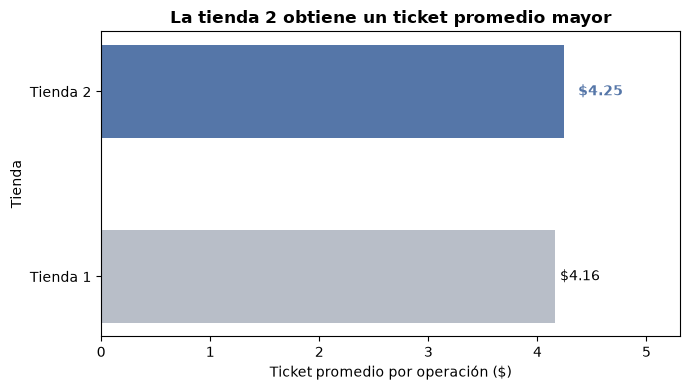

In [13]:
# ACTIVIDAD 3 GRÁFICO 2: TICKET PROMEDIO POR TIENDA

import matplotlib.pyplot as plt

# Preparamos los datos a partir de las métricas ya calculadas.
datos_ticket = df_metricas_pd[
    ["tienda_id", "ingreso_total", "cantidad_operaciones"]
].groupby("tienda_id", as_index=False).sum()

# Calculamos el ticket promedio por tienda.
datos_ticket["ticket_promedio"] = (
    datos_ticket["ingreso_total"]
    / datos_ticket["cantidad_operaciones"]
)

datos_ticket["tienda"] = (
    "Tienda " + datos_ticket["tienda_id"].astype(str)
)

# Destacamos únicamente la tienda con mayor ticket promedio.
indice_maximo = datos_ticket["ticket_promedio"].idxmax()

colores = [
    "#5576A8" if i == indice_maximo else "#B8BEC8"
    for i in datos_ticket.index
]

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.barh(
    datos_ticket["tienda"],
    datos_ticket["ticket_promedio"],
    color=colores,
    height=0.5
)

ax.set_title(
    "La tienda 2 obtiene un ticket promedio mayor",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Ticket promedio por operación ($)")
ax.set_ylabel("Tienda")
ax.set_xlim(0, datos_ticket["ticket_promedio"].max() * 1.25)

# Anotamos el valor más alto.
barra_destacada = barras[indice_maximo]

ax.annotate(
    f'${datos_ticket.loc[indice_maximo, "ticket_promedio"]:.2f}',
    xy=(
        barra_destacada.get_width(),
        barra_destacada.get_y() + barra_destacada.get_height() / 2
    ),
    xytext=(10, 0),
    textcoords="offset points",
    va="center",
    fontweight="bold",
    color="#5576A8"
)

# Etiquetamos el otro valor.
for i, barra in enumerate(barras):
    if i != indice_maximo:
        ax.text(
            barra.get_width() + 0.05,
            barra.get_y() + barra.get_height() / 2,
            f'${datos_ticket.loc[i, "ticket_promedio"]:.2f}',
            va="center"
        )

plt.tight_layout()

plt.savefig(
    "graficos/grafico_ticket_promedio.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Hallazgo 2 – La tienda 2 registra un ticket promedio ligeramente mayor

**¿Qué observamos?**

La tienda 2 presenta un ticket promedio de aproximadamente $4,25, mientras que la tienda 1 registra $4,16. La diferencia es de apenas $0,09 (aproximadamente un 2 %).

Aunque la tienda 2 realizó menos operaciones (7.990 frente a 8.054), obtuvo una facturación total ligeramente superior.

**¿Qué significa?**

La diferencia de facturación se relaciona con un importe promedio por pago algo mayor. Sin embargo, esta diferencia es reducida y no permite afirmar que el empleado de la tienda 2 tenga un mejor desempeño comercial.

**¿Qué decisión de negocio permite tomar?**

Antes de evaluar el rendimiento de los empleados, sería necesario analizar otras variables, como las tarifas de alquiler, la cantidad de clientes atendidos y las horas trabajadas. Esto permitiría realizar una comparación más justa y fundamentada.

/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_7152/552624577.py:27: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_evolucion = pd.read_sql(consulta_evolucion, conexion)


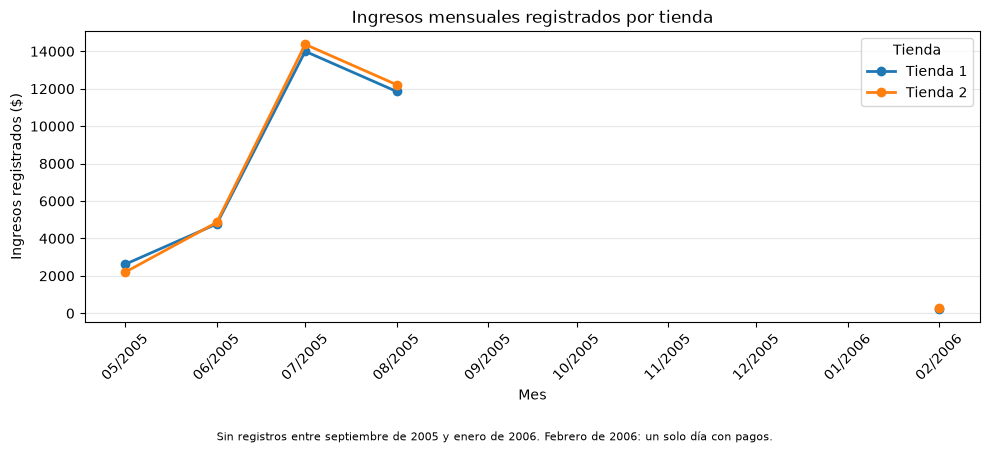

,tienda_id,anio,mes,ingreso_mensual,dias_con_pagos,periodo
0,1,2005,5,2621.83,8,2005-05-01
1,2,2005,5,2201.61,8,2005-05-01
2,1,2005,6,4774.37,8,2005-06-01
3,2,2005,6,4855.52,8,2005-06-01
4,1,2005,7,13998.56,14,2005-07-01
5,2,2005,7,14370.35,14,2005-07-01
6,1,2005,8,11853.65,10,2005-08-01
7,2,2005,8,12216.49,10,2005-08-01
8,1,2006,2,234.09,1,2006-02-01
9,2,2006,2,280.09,1,2006-02-01


In [15]:

# ACTIVIDAD 3 - GRÁFICO 3: EVOLUCIÓN MENSUAL DE INGRESOS

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# Consultamos los ingresos mensuales por tienda.
consulta_evolucion = f"""
SELECT
    e.{nombre_columna_sql('staff', 'store_id')} AS tienda_id,
    YEAR(p.{nombre_columna_sql('payment', 'payment_date')}) AS anio,
    MONTH(p.{nombre_columna_sql('payment', 'payment_date')}) AS mes,
    SUM(p.{nombre_columna_sql('payment', 'amount')}) AS ingreso_mensual,
    COUNT(DISTINCT CAST(p.{nombre_columna_sql('payment', 'payment_date')} AS date)) AS dias_con_pagos
FROM {nombre_tabla_sql('payment')} AS p
INNER JOIN {nombre_tabla_sql('staff')} AS e
    ON p.{nombre_columna_sql('payment', 'staff_id')} =
       e.{nombre_columna_sql('staff', 'staff_id')}
GROUP BY
    e.{nombre_columna_sql('staff', 'store_id')},
    YEAR(p.{nombre_columna_sql('payment', 'payment_date')}),
    MONTH(p.{nombre_columna_sql('payment', 'payment_date')})
ORDER BY anio, mes, tienda_id;
"""

df_evolucion = pd.read_sql(consulta_evolucion, conexion)

df_evolucion["periodo"] = pd.to_datetime(
    dict(
        year=df_evolucion["anio"],
        month=df_evolucion["mes"],
        day=1
    )
)

# Incluimos todos los meses del intervalo.
# Los meses sin registros quedan como NaN, no como cero.
meses = pd.date_range(
    df_evolucion["periodo"].min(),
    df_evolucion["periodo"].max(),
    freq="MS"
)

fig, ax = plt.subplots(figsize=(10, 4.5))

for tienda_id, datos in df_evolucion.groupby("tienda_id"):
    serie = (
        datos.set_index("periodo")["ingreso_mensual"]
        .reindex(meses)
    )

    # Matplotlib interrumpe la línea donde hay NaN.
    ax.plot(
        serie.index,
        serie.values,
        marker="o",
        linewidth=2,
        label=f"Tienda {tienda_id}"
    )

ax.set_title("Ingresos mensuales registrados por tienda")
ax.set_xlabel("Mes")
ax.set_ylabel("Ingresos registrados ($)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Tienda")

plt.xticks(rotation=45)

# Aclaración sobre la cobertura de los datos.
fig.text(
    0.5, 0.01,
    "Sin registros entre septiembre de 2005 y enero de 2006. "
    "Febrero de 2006: un solo día con pagos.",
    ha="center",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

Path("graficos").mkdir(exist_ok=True)

plt.savefig(
    "graficos/grafico_evolucion_mensual.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(df_evolucion)


### Hallazgo 3 – Julio de 2005 concentra los mayores ingresos registrados

**¿Qué observamos?**

El gráfico de líneas muestra la evolución mensual de los ingresos de ambas tiendas durante los períodos con pagos registrados.

Julio de 2005 fue el mes de mayor facturación para ambas sucursales:

- **Tienda 1:** $13.998,56.
- **Tienda 2:** $14.370,35.

Durante los meses observados, la tienda 2 registró ingresos superiores a los de la tienda 1 en junio, julio, agosto de 2005 y febrero de 2006. La tienda 1 obtuvo mayores ingresos en mayo de 2005.

**¿Qué explica este comportamiento?**

Los datos muestran una concentración de ingresos en julio y agosto de 2005, seguida de un importe mucho menor en febrero de 2006.

Sin embargo, no es posible afirmar que exista una tendencia estacional ni que las ventas hayan disminuido de forma sostenida, porque faltan registros de varios meses y no se conoce si todos los períodos tienen la misma cobertura de datos.

**¿Qué decisión de negocio permite tomar?**

Se recomienda investigar qué factores explican la concentración de ingresos en julio y agosto, revisando la cantidad de operaciones, los alquileres y la cobertura temporal de los registros.

Si se confirma que los datos son completos y que el comportamiento se repite en otros años, esta información podría utilizarse para planificar recursos y personal en los meses de mayor actividad.

**Limitación del análisis:** El gráfico presenta únicamente los meses con registros disponibles. Las líneas conectan observaciones, pero no representan ingresos conocidos de los meses intermedios.